# Thresholding

Thresholding turns a grayscale image into a binary one - foreground white, background black - by comparing every pixel with a cut-off value. It is the bridge between raw images and measurement: once an image is binary you can count, measure and find objects. This notebook covers simple, adaptive and Otsu thresholding, plus threshold types and inRange.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Simple (global) thresholding

`cv2.threshold` with `THRESH_BINARY` sets pixels above the threshold to maxValue and the rest to 0. It also returns the threshold used. It works well only when foreground and background brightness are clearly separated and lighting is even.

Threshold used: 127.0 | white pixels: 28703


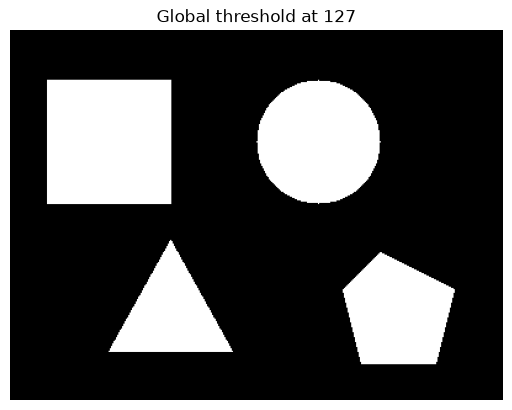

In [2]:
gray = cv2.cvtColor(cv2.imread("../assets/contours_shapes.png"), cv2.COLOR_BGR2GRAY)
ret, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
print("Threshold used:", ret, "| white pixels:", int((binary > 0).sum()))
show(binary, "Global threshold at 127")

## The five threshold types

THRESH_BINARY, BINARY_INV, TRUNC (cap values at the threshold), TOZERO (keep only above) and TOZERO_INV change what happens on each side of the cut-off. Choosing the inverted variant when the object is dark on a light background is the most common practical decision.

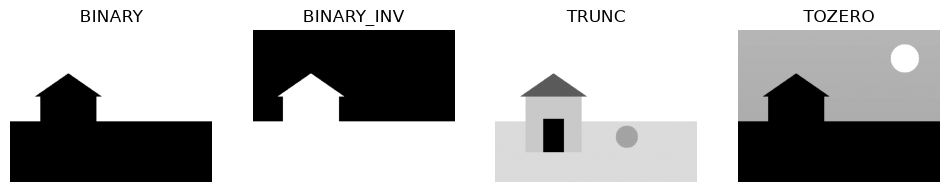

In [3]:
img = cv2.imread("../assets/test_image.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
types = [(cv2.THRESH_BINARY, "BINARY"), (cv2.THRESH_BINARY_INV, "BINARY_INV"),
         (cv2.THRESH_TRUNC, "TRUNC"), (cv2.THRESH_TOZERO, "TOZERO")]
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, (t, name) in zip(axes, types):
    _, out = cv2.threshold(gray, 120, 255, t)
    ax.imshow(out, cmap="gray"); ax.set_title(name); ax.axis("off")
plt.show()

## Otsu's method - automatic threshold selection

Otsu's method chooses the threshold that best separates the histogram into two classes - pass threshold 0 with `THRESH_OTSU` and OpenCV finds it. It is the right default when you do not know the lighting in advance.

Otsu chose threshold: 147.0


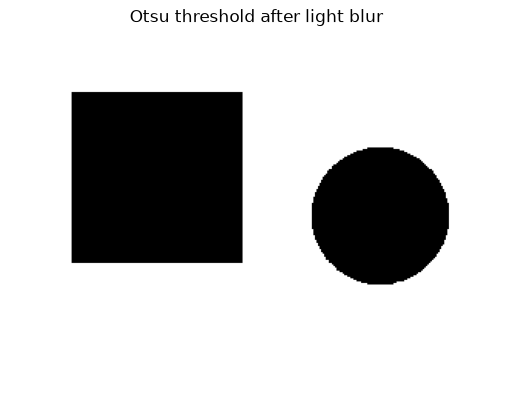

In [4]:
noisy = cv2.imread("../assets/noisy_image.png")
gray_n = cv2.cvtColor(noisy, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray_n, (5, 5), 0)
otsu_value, otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu chose threshold:", otsu_value)
show(otsu, "Otsu threshold after light blur")

## Adaptive thresholding for uneven lighting

When one corner of the image is brighter than another, no single global value works. Adaptive thresholding computes a local threshold per neighbourhood: `ADAPTIVE_THRESH_MEAN_C` uses the local mean, `GAUSSIAN_C` a weighted mean. blockSize must be odd; C is a constant subtracted from the mean.

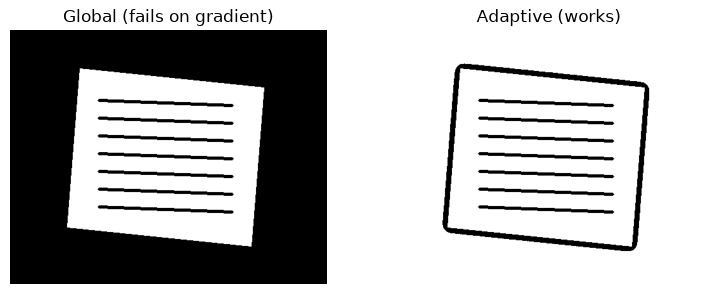

In [5]:
doc = cv2.imread("../assets/document.png")
gray_d = cv2.cvtColor(doc, cv2.COLOR_BGR2GRAY)
# simulate uneven lighting with a gradient
gradient = np.tile(np.linspace(0, 90, gray_d.shape[1]), (gray_d.shape[0], 1))
uneven = np.clip(gray_d.astype(np.float32) + gradient - 45, 0, 255).astype(np.uint8)
_, global_t = cv2.threshold(uneven, 150, 255, cv2.THRESH_BINARY)
adaptive = cv2.adaptiveThreshold(uneven, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 10)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(global_t, cmap="gray"); axes[0].set_title("Global (fails on gradient)")
axes[1].imshow(adaptive, cmap="gray"); axes[1].set_title("Adaptive (works)")
for ax in axes: ax.axis("off")
plt.show()

## inRange as multi-channel thresholding

`cv2.inRange` is thresholding for colour images: lower and upper bounds per channel produce a mask. On a single grayscale channel it behaves like a band-pass threshold, keeping only a brightness band.

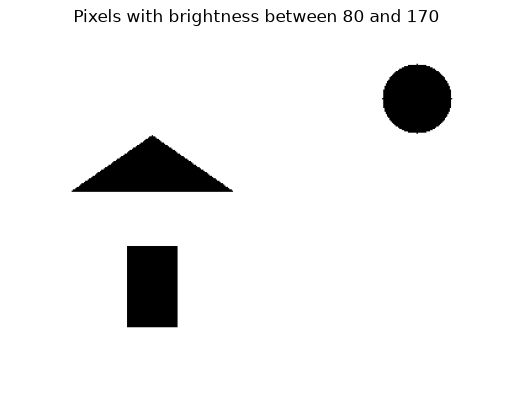

Band pixels: 111785


In [6]:
gray_img = cv2.cvtColor(cv2.imread("../assets/test_image.png"), cv2.COLOR_BGR2GRAY)
band = cv2.inRange(gray_img, 80, 170)
show(band, "Pixels with brightness between 80 and 170")
print("Band pixels:", int((band > 0).sum()))

## Cleaning a binary image

Real thresholded images have specks and holes. The quick fixes previewed here - a median blur before thresholding, and morphology after - are covered fully in notebook 08. Even this simple pipeline dramatically improves downstream contour results.

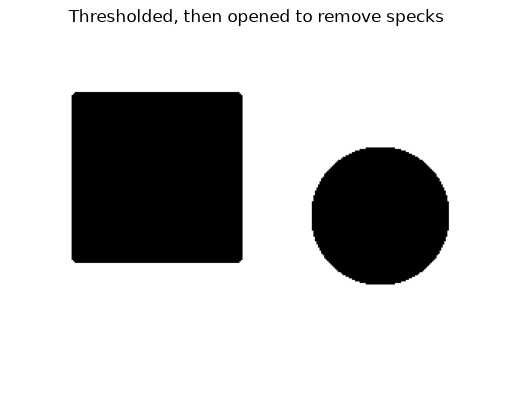

In [7]:
raw = cv2.imread("../assets/noisy_image.png")
g = cv2.medianBlur(cv2.cvtColor(raw, cv2.COLOR_BGR2GRAY), 5)
_, clean = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
kernel = np.ones((3, 3), np.uint8)
clean = cv2.morphologyEx(clean, cv2.MORPH_OPEN, kernel)
show(clean, "Thresholded, then opened to remove specks")

## Key Points

- Global thresholding needs even lighting and a clear brightness separation.
- Otsu (THRESH_OTSU with value 0) picks the threshold automatically from the histogram.
- Adaptive thresholding computes a local cut-off - use it for documents and uneven light.
- BINARY_INV is for dark objects on light backgrounds.
- Threshold first, then clean with morphology - order matters.

## Mini Task

1. Apply Otsu to `noisy_image.png` without the pre-blur and compare the chosen value with the blurred version.
2. Use adaptive thresholding on `document.png` with blockSize 11 and 51 and describe the difference.
3. Build an inRange band that keeps only the darkest pixels of `test_image.png`.